In [ ]:
# Block 1: Import libraries and load data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('TIA-WEATHER-DATA-2015-01-01-TO-2025-06-30 (1).csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values('datetime')

In [ ]:
df.head()

,datetime,tempmax,tempmin,temp,dew,humidity,precipprob,precipcover,preciptype,windgust,...,temp_rate_change,pressure_rate_change,humidity_rate_change,temp_anomaly_7,pressure_anomaly_7,humidity_anomaly_7,accumulated_precip_7,accumulated_precip_30,rain_binary,precipitation_log
0,2015-01-01,60.7,39.1,50.0,41.7,74.7,100,4.17,rain,11.2,...,NaN,NaN,NaN,0.000000,0.000,0.000000,0.8,0.8,1,0.587787
1,2015-01-02,71.0,49.9,54.9,48.4,80.1,100,20.83,rain,19.9,...,0.098000,0.001764,0.072289,2.450000,0.900,2.700000,0.8,0.8,0,0.000000
2,2015-01-03,67.7,48.1,54.8,50.5,86.3,100,8.33,rain,15.4,...,-0.001821,-0.001174,0.077403,1.566667,-0.200,5.933333,1.3,1.3,1,0.405465
3,2015-01-04,69.9,48.1,54.5,49.6,85.5,100,4.17,rain,17.0,...,-0.005474,-0.002840,-0.009270,0.950000,-2.325,3.850000,1.8,1.8,1,0.405465
4,2015-01-05,64.3,42.7,51.3,45.7,83.2,0,0.00,NaN,16.3,...,-0.058716,-0.004125,-0.026901,-1.800000,-5.220,1.240000,1.8,1.8,0,0.000000


In [ ]:
# Block 2: Feature engineering
df = df.sort_values('datetime')

df['temp_range'] = df['tempmax'] - df['tempmin']
df['dew_point_depression'] = df['temp'] - df['dew']
df['humidity_deficit'] = 100 - df['humidity']
df['temp_dew_ratio'] = df['temp'] / (df['dew'] + 0.01)

df['pressure_trend'] = df['sealevelpressure'].diff(1)
df['pressure_trend_3'] = df['sealevelpressure'].diff(3)
df['pressure_acceleration'] = df['pressure_trend'].diff(1)

df['wind_power'] = df['windspeed'] ** 3
df['wind_gust_ratio'] = df['windgust'] / (df['windspeed'] + 0.01)
df['wind_energy'] = 0.5 * df['windspeed'] ** 2

df['cloud_cover_ratio'] = df['cloudcover'] / 100
df['solar_efficiency'] = df['solarenergy'] / (df['solarradiation'] + 0.01)
df['uv_radiation_ratio'] = df['uvindex'] / (df['solarradiation'] + 0.01)

df['hour'] = df['datetime'].dt.hour
df['month'] = df['datetime'].dt.month
df['dayofyear'] = df['datetime'].dt.dayofyear

df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
df['day_sin'] = np.sin(2 * np.pi * df['dayofyear'] / 365)
df['day_cos'] = np.cos(2 * np.pi * df['dayofyear'] / 365)

df['temp_humidity_interaction'] = df['temp'] * df['humidity']
df['pressure_cloud_interaction'] = df['sealevelpressure'] * df['cloudcover']
df['wind_cloud_interaction'] = df['windspeed'] * df['cloudcover']

for lag in [1, 2, 3, 7, 14, 30]:
    df[f'precip_lag_{lag}'] = df['precipitation'].shift(lag)
    df[f'temp_lag_{lag}'] = df['temp'].shift(lag)
    df[f'humidity_lag_{lag}'] = df['humidity'].shift(lag)
    df[f'pressure_lag_{lag}'] = df['sealevelpressure'].shift(lag)
    df[f'cloud_lag_{lag}'] = df['cloudcover'].shift(lag)
    df[f'wind_lag_{lag}'] = df['windspeed'].shift(lag)

for window in [3, 7, 14, 30]:
    df[f'temp_roll_mean_{window}'] = df['temp'].rolling(window=window, min_periods=1).mean()
    df[f'temp_roll_std_{window}'] = df['temp'].rolling(window=window, min_periods=1).std()
    df[f'temp_roll_max_{window}'] = df['temp'].rolling(window=window, min_periods=1).max()
    df[f'temp_roll_min_{window}'] = df['temp'].rolling(window=window, min_periods=1).min()

    df[f'humidity_roll_mean_{window}'] = df['humidity'].rolling(window=window, min_periods=1).mean()
    df[f'humidity_roll_std_{window}'] = df['humidity'].rolling(window=window, min_periods=1).std()

    df[f'pressure_roll_mean_{window}'] = df['sealevelpressure'].rolling(window=window, min_periods=1).mean()
    df[f'pressure_roll_std_{window}'] = df['sealevelpressure'].rolling(window=window, min_periods=1).std()

    df[f'precip_roll_sum_{window}'] = df['precipitation'].rolling(window=window, min_periods=1).sum()
    df[f'precip_roll_mean_{window}'] = df['precipitation'].rolling(window=window, min_periods=1).mean()

    df[f'cloud_roll_mean_{window}'] = df['cloudcover'].rolling(window=window, min_periods=1).mean()

df['temp_rate_change'] = df['temp'].pct_change(1)
df['pressure_rate_change'] = df['sealevelpressure'].pct_change(1)
df['humidity_rate_change'] = df['humidity'].pct_change(1)

df['temp_anomaly_7'] = df['temp'] - df['temp_roll_mean_7']
df['pressure_anomaly_7'] = df['sealevelpressure'] - df['pressure_roll_mean_7']
df['humidity_anomaly_7'] = df['humidity'] - df['humidity_roll_mean_7']

df['accumulated_precip_7'] = df['precipitation'].rolling(window=7, min_periods=1).sum()
df['accumulated_precip_30'] = df['precipitation'].rolling(window=30, min_periods=1).sum()

df['rain_binary'] = (df['precipitation'] > 0).astype(int)
df['precipitation_log'] = np.log1p(df['precipitation'])

In [ ]:
# Block 3: Feature selection
from sklearn.feature_selection import SelectKBest, mutual_info_regression, RFE
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

target_reg = 'precipitation_log'
features_to_use = [col for col in df.columns if col not in ['datetime', 'precipitation', 'precipitation_log',
                                                             'rain_binary', 'preciptype', 'sunrise', 'sunset']]

features_to_use = [col for col in features_to_use if df[col].dtype in ['float64', 'int64']]

df_features = df[features_to_use].fillna(df[features_to_use].median())

reg_mask = df['precipitation'] > 0
X_reg_all = df_features[reg_mask]
y_reg_all = df.loc[reg_mask, target_reg]

mi_scores = mutual_info_regression(X_reg_all, y_reg_all, random_state=42)
mi_selected = pd.DataFrame({'feature': features_to_use, 'mi_score': mi_scores})
mi_selected = mi_selected.sort_values('mi_score', ascending=False)

rf_selector = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_selector.fit(X_reg_all, y_reg_all)
rf_importance = pd.DataFrame({'feature': features_to_use, 'rf_importance': rf_selector.feature_importances_})
rf_importance = rf_importance.sort_values('rf_importance', ascending=False)

feature_scores = mi_selected.merge(rf_importance, on='feature')
feature_scores['combined_score'] = (feature_scores['mi_score'] / feature_scores['mi_score'].max()) + \
                                     (feature_scores['rf_importance'] / feature_scores['rf_importance'].max())
feature_scores = feature_scores.sort_values('combined_score', ascending=False)

top_features = feature_scores.head(50)['feature'].tolist()

In [ ]:
# Block 4: Data splitting and preprocessing
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.preprocessing import PowerTransformer, QuantileTransformer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor, StackingRegressor, VotingRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

split_idx = int(len(df) * 0.8)
train_dates = df.iloc[:split_idx]['datetime']
test_dates = df.iloc[split_idx:]['datetime']

reg_mask = df['precipitation'] > 0
X_reg = df.loc[reg_mask, top_features].fillna(df.loc[reg_mask, top_features].median())
y_reg = df.loc[reg_mask, 'precipitation_log']

train_idx = df.loc[reg_mask, 'datetime'] < train_dates.iloc[-1]
test_idx = df.loc[reg_mask, 'datetime'] >= train_dates.iloc[-1]

X_train_reg = X_reg[train_idx]
X_test_reg = X_reg[test_idx]
y_train_reg = y_reg[train_idx]
y_test_reg = y_reg[test_idx]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_reg)
X_test_scaled = scaler.transform(X_test_reg)

power_transformer = PowerTransformer(method='yeo-johnson')
X_train_transformed = power_transformer.fit_transform(X_train_scaled)
X_test_transformed = power_transformer.transform(X_test_scaled)

In [ ]:
# Block 5: Train individual models
models = {
    'XGBoost': XGBRegressor(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),
    'LightGBM': LGBMRegressor(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    ),
    'RandomForest': RandomForestRegressor(
        n_estimators=300,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
}

results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_transformed, y_train_reg)

    y_pred_log = model.predict(X_test_transformed)
    y_pred = np.expm1(y_pred_log)
    y_actual = np.expm1(y_test_reg)

    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    mae = mean_absolute_error(y_actual, y_pred)
    r2 = r2_score(y_actual, y_pred)
    mape = np.mean(np.abs((y_actual - y_pred) / (y_actual + 0.01))) * 100

    results[name] = {'RMSE': rmse, 'MAE': mae, 'R2': r2, 'MAPE': mape}
    predictions[name] = y_pred

In [ ]:
# Block 6: Train ensemble models
from sklearn.ensemble import StackingRegressor, VotingRegressor
from sklearn.linear_model import Ridge

voting_ensemble = VotingRegressor(
    estimators=[
        ('xgb', models['XGBoost']),
        ('lgbm', models['LightGBM']),
        ('rf', models['RandomForest'])
    ],
    weights=[0.3, 0.3, 0.4]
)

voting_ensemble.fit(X_train_transformed, y_train_reg)

y_pred_voting_log = voting_ensemble.predict(X_test_transformed)
y_pred_voting = np.expm1(y_pred_voting_log)

rmse_voting = np.sqrt(mean_squared_error(y_actual, y_pred_voting))
mae_voting = mean_absolute_error(y_actual, y_pred_voting)
r2_voting = r2_score(y_actual, y_pred_voting)
mape_voting = np.mean(np.abs((y_actual - y_pred_voting) / (y_actual + 0.01))) * 100

results['VotingEnsemble'] = {'RMSE': rmse_voting, 'MAE': mae_voting, 'R2': r2_voting, 'MAPE': mape_voting}
predictions['VotingEnsemble'] = y_pred_voting

base_models = [
    ('xgb', models['XGBoost']),
    ('lgbm', models['LightGBM']),
    ('rf', models['RandomForest'])
]

stacking_ensemble = StackingRegressor(
    estimators=base_models,
    final_estimator=Ridge(alpha=1.0),
    cv=5,
    passthrough=False
)

stacking_ensemble.fit(X_train_transformed, y_train_reg)

y_pred_stacking_log = stacking_ensemble.predict(X_test_transformed)
y_pred_stacking = np.expm1(y_pred_stacking_log)

rmse_stacking = np.sqrt(mean_squared_error(y_actual, y_pred_stacking))
mae_stacking = mean_absolute_error(y_actual, y_pred_stacking)
r2_stacking = r2_score(y_actual, y_pred_stacking)
mape_stacking = np.mean(np.abs((y_actual - y_pred_stacking) / (y_actual + 0.01))) * 100

results['StackingEnsemble'] = {'RMSE': rmse_stacking, 'MAE': mae_stacking, 'R2': r2_stacking, 'MAPE': mape_stacking}
predictions['StackingEnsemble'] = y_pred_stacking

In [ ]:
# Block 7: Hyperparameter tuning for XGBoost
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [300, 500, 700, 1000],
    'max_depth': [6, 8, 10, 12],
    'learning_rate': [0.01, 0.03, 0.05, 0.07, 0.1],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'min_child_weight': [1, 3, 5, 7],
    'gamma': [0, 0.1, 0.2, 0.3]
}

xgb_tuned = XGBRegressor(random_state=42, n_jobs=-1)

random_search = RandomizedSearchCV(
    xgb_tuned,
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=0
)

random_search.fit(X_train_transformed, y_train_reg)

best_xgb = random_search.best_estimator_
y_pred_best_log = best_xgb.predict(X_test_transformed)
y_pred_best = np.expm1(y_pred_best_log)

rmse_best = np.sqrt(mean_squared_error(y_actual, y_pred_best))
mae_best = mean_absolute_error(y_actual, y_pred_best)
r2_best = r2_score(y_actual, y_pred_best)
mape_best = np.mean(np.abs((y_actual - y_pred_best) / (y_actual + 0.01))) * 100

results['XGBoost_Tuned'] = {'RMSE': rmse_best, 'MAE': mae_best, 'R2': r2_best, 'MAPE': mape_best}
predictions['XGBoost_Tuned'] = y_pred_best

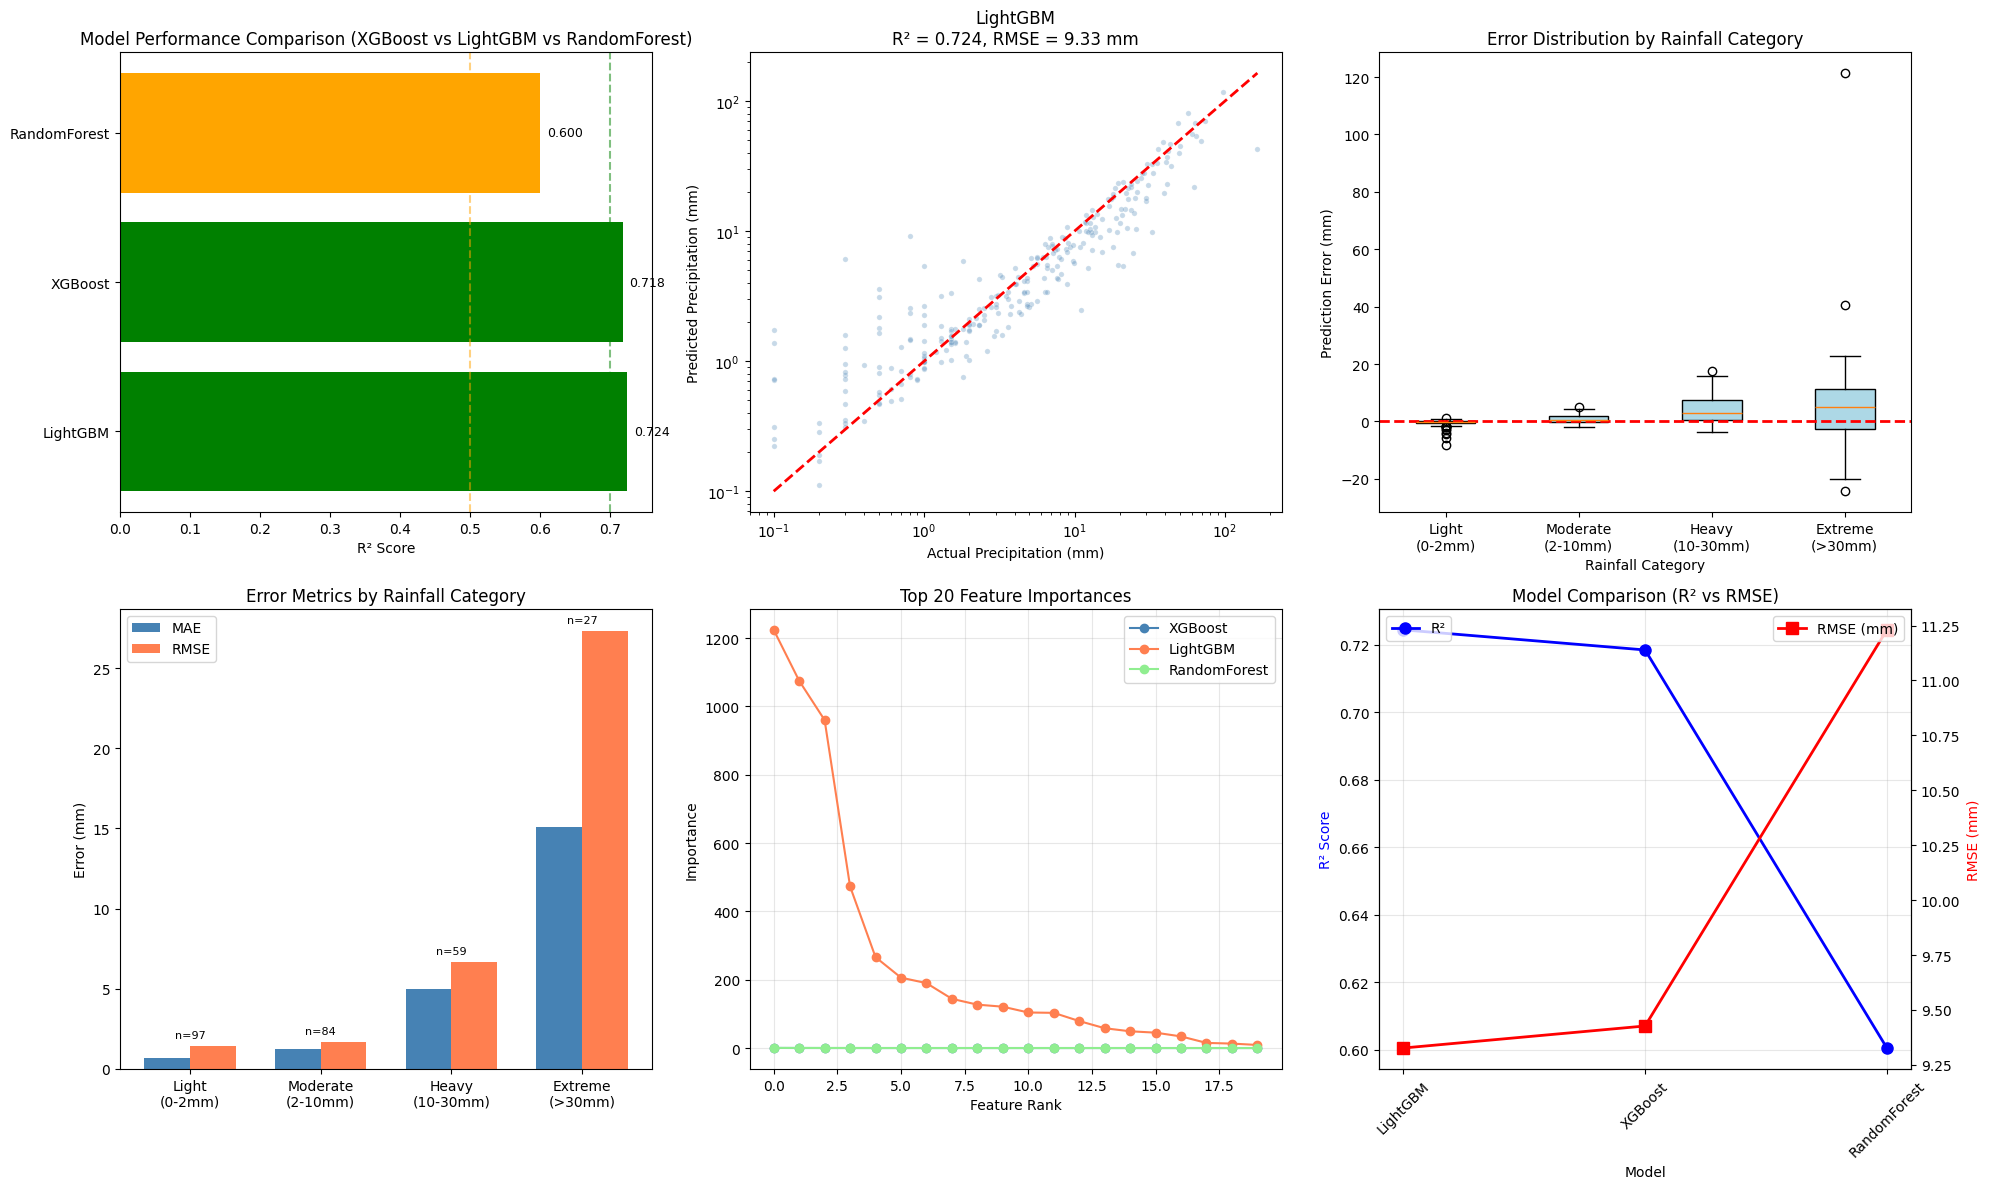

In [15]:
# Filter results to only the 3 models
models_to_show = ['XGBoost_Tuned', 'LightGBM', 'RandomForest']
display_names = {'XGBoost_Tuned': 'XGBoost', 'LightGBM': 'LightGBM', 'RandomForest': 'RandomForest'}

results_df = pd.DataFrame(results).T
results_df = results_df[results_df.index.isin(models_to_show)]
results_df = results_df.sort_values('R2', ascending=False)
results_df.index = results_df.index.map(display_names)

predictions_display = {display_names[k]: v for k, v in predictions.items() if k in models_to_show}
models_display = {display_names[k]: models[k] if k != 'XGBoost_Tuned' else best_xgb for k in models_to_show}

plt.figure(figsize=(20, 12))

ax1 = plt.subplot(2, 3, 1)
models_names = results_df.index.tolist()
r2_scores = results_df['R2'].values
colors = ['green' if x >= 0.7 else 'orange' if x >= 0.5 else 'red' for x in r2_scores]
bars = ax1.barh(models_names, r2_scores, color=colors)
ax1.axvline(x=0.7, color='green', linestyle='--', alpha=0.5)
ax1.axvline(x=0.5, color='orange', linestyle='--', alpha=0.5)
ax1.set_xlabel('R² Score')
ax1.set_title('Model Performance Comparison (XGBoost vs LightGBM vs RandomForest)')

for i, (bar, score) in enumerate(zip(bars, r2_scores)):
    ax1.text(score + 0.01, bar.get_y() + bar.get_height()/2,
             f'{score:.3f}', va='center', fontsize=9)

ax2 = plt.subplot(2, 3, 2)
best_model_name = results_df.index[0]
best_pred = predictions_display[best_model_name]

ax2.scatter(y_actual, best_pred, alpha=0.3, s=15, c='steelblue', edgecolors='white', linewidth=0.5)
ax2.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()],
         'r--', lw=2)
ax2.set_xlabel('Actual Precipitation (mm)')
ax2.set_ylabel('Predicted Precipitation (mm)')
ax2.set_title(f'{best_model_name}\nR² = {results_df.iloc[0]["R2"]:.3f}, RMSE = {results_df.iloc[0]["RMSE"]:.2f} mm')
ax2.set_xscale('log')
ax2.set_yscale('log')

ax3 = plt.subplot(2, 3, 3)
residuals = y_actual - best_pred
df_residuals = pd.DataFrame({
    'actual': y_actual,
    'residual': residuals
})
df_residuals['category'] = pd.cut(df_residuals['actual'],
                                   bins=[0, 2, 10, 30, 1000],
                                   labels=['Light\n(0-2mm)', 'Moderate\n(2-10mm)',
                                           'Heavy\n(10-30mm)', 'Extreme\n(>30mm)'])

box_data = [df_residuals[df_residuals['category'] == cat]['residual']
            for cat in df_residuals['category'].cat.categories]
bp = ax3.boxplot(box_data, labels=df_residuals['category'].cat.categories, patch_artist=True)
for patch in bp['boxes']:
    patch.set_facecolor('lightblue')
ax3.axhline(y=0, color='r', linestyle='--', lw=2)
ax3.set_xlabel('Rainfall Category')
ax3.set_ylabel('Prediction Error (mm)')
ax3.set_title('Error Distribution by Rainfall Category')

ax4 = plt.subplot(2, 3, 4)
category_errors = df_residuals.groupby('category').apply(
    lambda x: pd.Series({
        'MAE': np.abs(x['residual']).mean(),
        'RMSE': np.sqrt((x['residual']**2).mean()),
        'Count': len(x)
    })
)

x = np.arange(len(category_errors))
width = 0.35
ax4.bar(x - width/2, category_errors['MAE'], width, label='MAE', color='steelblue')
ax4.bar(x + width/2, category_errors['RMSE'], width, label='RMSE', color='coral')
ax4.set_xticks(x)
ax4.set_xticklabels(category_errors.index)
ax4.set_ylabel('Error (mm)')
ax4.set_title('Error Metrics by Rainfall Category')
ax4.legend()

for i, (idx, row) in enumerate(category_errors.iterrows()):
    ax4.text(i, max(row['MAE'], row['RMSE']) + 0.5, f'n={int(row["Count"])}',
             ha='center', fontsize=8)

ax5 = plt.subplot(2, 3, 5)
model_colors = {'XGBoost': 'steelblue', 'LightGBM': 'coral', 'RandomForest': 'lightgreen'}
for model_name, model_obj in models_display.items():
    importances = model_obj.feature_importances_[:20]
    ax5.plot(range(len(importances)), sorted(importances, reverse=True),
             marker='o', label=model_name, color=model_colors[model_name])

ax5.set_xlabel('Feature Rank')
ax5.set_ylabel('Importance')
ax5.set_title('Top 20 Feature Importances')
ax5.legend()
ax5.grid(True, alpha=0.3)

ax6 = plt.subplot(2, 3, 6)
models_ordered = results_df.index.tolist()
r2_progression = results_df['R2'].values
rmse_progression = results_df['RMSE'].values

ax6_twin = ax6.twinx()
ax6.plot(models_ordered, r2_progression, 'b-o', linewidth=2, markersize=8, label='R²')
ax6_twin.plot(models_ordered, rmse_progression, 'r-s', linewidth=2, markersize=8, label='RMSE (mm)')

ax6.set_xlabel('Model')
ax6.set_ylabel('R² Score', color='b')
ax6_twin.set_ylabel('RMSE (mm)', color='r')
ax6.set_title('Model Comparison (R² vs RMSE)')
ax6.tick_params(axis='x', rotation=45)
ax6.legend(loc='upper left')
ax6_twin.legend(loc='upper right')
ax6.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
import joblib
import os

model_dir = "/content/Modles_pkl"
os.makedirs(model_dir, exist_ok=True)

joblib.dump(models['RandomForest'], os.path.join(model_dir, "random_forest_model.pkl"))
joblib.dump(models['LightGBM'], os.path.join(model_dir, "lightgbm_model.pkl"))
joblib.dump(best_xgb, os.path.join(model_dir, "xgboost_tuned_model.pkl"))
joblib.dump(scaler, os.path.join(model_dir, "scaler.pkl"))
joblib.dump(top_features, os.path.join(model_dir, "selected_features.pkl"))

print("Models saved successfully to:", model_dir)

Models saved successfully to: /content/Modles_pkl
